[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/03_query_key_value.ipynb)

# 03 · The Core Idea: Query, Key, Value

*Attention, Explained · Hamza Hentabli, Ph.D. · ~25 min*

Attention sounds mysterious, but it is a small generalisation of something every programmer uses: a **dictionary lookup**. In this notebook we turn a hard lookup into a *soft* one, and discover the three ingredients of every attention layer — **queries, keys and values**.

**Learning objectives.** By the end of this notebook you will be able to:

- describe attention as a **soft, differentiable dictionary lookup**
- compute attention weights and outputs for a small worked example
- explain how the **scale** of the scores moves between soft averaging and hard lookup
- explain where **Q, K and V** come from ($W_Q, W_K, W_V$) and their shapes

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. A normal dictionary: hard lookup

A Python dictionary maps **keys** to **values**. You ask with a **query**; if it matches a key *exactly* you get that value, otherwise nothing.

In [2]:
prices = {"apple": 0.50, "banana": 0.25, "cherry": 3.00}
print(prices["banana"])
try:
    prices["bananna"]
except KeyError as err:
    print("KeyError:", err, "- a hard lookup needs an exact match")

0.25
KeyError: 'bananna' - a hard lookup needs an exact match


## 2. A soft dictionary: attention

Attention changes three things:

1. queries and keys are **vectors**, and matching is **graded** — measured by a dot product, not by equality;
2. the match scores are turned into **weights that sum to 1** with a softmax;
3. instead of returning one value, it returns the **weighted average of all values**.

$$\text{output} = \sum_i \text{softmax}(q \cdot k_i)\; v_i$$

### Worked example: asking a tiny library

Four books. Each book's **key** describes its topic on three axes `[biology, chemistry, computing]`. Each book's **value** is what we get back — here a 2-number summary `[difficulty, pages/100]`.

In [3]:
books  = ["Cell Biology", "Organic Chemistry", "Python Basics", "Cheminformatics"]
K = np.array([[1.0, 0.1, 0.0],     # Cell Biology        -> mostly biology
              [0.1, 1.0, 0.0],     # Organic Chemistry   -> mostly chemistry
              [0.0, 0.0, 1.0],     # Python Basics       -> computing
              [0.0, 0.8, 0.8]])    # Cheminformatics     -> chemistry + computing
V = np.array([[3.0, 6.0],
              [4.0, 9.0],
              [1.0, 3.0],
              [4.5, 4.0]])

q = np.array([0.0, 1.0, 1.0])      # "I want chemistry AND computing"
scores  = K @ q                    # one dot product per key
weights = au.softmax(scores)
output  = weights @ V

for b, s, w in zip(books, scores, weights):
    print(f"{b:18s} score = {s:4.2f}   weight = {w:.3f}")
print("\nweights sum to", weights.sum().round(6))
print("output (weighted average of values) =", output)

Cell Biology       score = 0.10   weight = 0.096
Organic Chemistry  score = 1.00   weight = 0.236
Python Basics      score = 1.00   weight = 0.236
Cheminformatics    score = 1.60   weight = 0.431

weights sum to 1.0
output (weighted average of values) = [3.41  5.138]


The *Cheminformatics* book matches best and gets the largest weight, but the others still contribute a little. The output is a **blend**, dominated by the most relevant value. Because everything is smooth, a neural network can learn the vectors by gradient descent — something impossible with an exact-match dictionary.

## 3. From soft to hard: the role of scale

If we multiply the scores by a large number before the softmax, the biggest score wins almost everything — attention becomes nearly a hard lookup. Multiply by a small number and the weights become uniform (a plain average). Keep this in mind: it is exactly why Notebook 04 divides by $\sqrt{d}$.

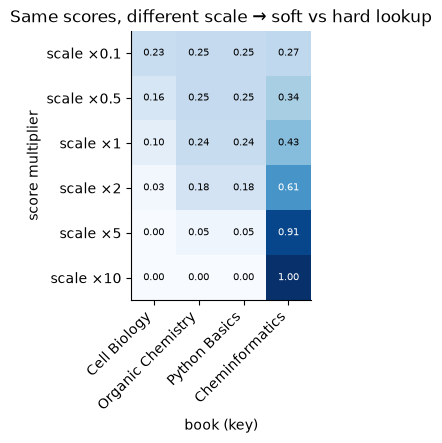

In [4]:
scales = [0.1, 0.5, 1, 2, 5, 10]
W_scale = np.array([au.softmax(s * scores) for s in scales])
fig, ax = plt.subplots(figsize=(7, 3.5))
au.plot_attention(W_scale, [f"scale ×{s}" for s in scales], books, ax=ax,
                  title="Same scores, different scale → soft vs hard lookup")
ax.set_ylabel("score multiplier"); ax.set_xlabel("book (key)")
plt.show()

## 4. Where do Q, K and V come from?

In a real model, the queries, keys and values are not hand-written. **Every token produces all three** from its own embedding $x$ using three learned matrices:

$$q = x W_Q, \qquad k = x W_K, \qquad v = x W_V$$

Think of each token at a meeting:

- **Query** — *what am I looking for?*
- **Key** — *what do I have to offer? (used for matching)*
- **Value** — *what I actually hand over if someone picks me.*

Using separate matrices lets a word be *matched* on one property but *contribute* a different one. Below: 4 tokens, embedding size 6, and projection size 3. The weights are random here (Notebooks 06 and 11 train them).

In [5]:
rng = np.random.default_rng(0)
tokens = ["the", "cat", "sat", "down"]
d_model, d_k = 6, 3
X  = rng.normal(size=(len(tokens), d_model))       # one embedding row per token
WQ = rng.normal(size=(d_model, d_k)) / np.sqrt(d_model)
WK = rng.normal(size=(d_model, d_k)) / np.sqrt(d_model)
WV = rng.normal(size=(d_model, d_k)) / np.sqrt(d_model)

Q, K_, V_ = X @ WQ, X @ WK, X @ WV
print("X :", X.shape, " W_Q:", WQ.shape, " ->  Q:", Q.shape, " K:", K_.shape, " V:", V_.shape)
S = Q @ K_.T                                  # every query against every key
A = au.softmax(S / np.sqrt(d_k), axis=-1)     # (the /sqrt(d_k) is explained in Notebook 04)
Z = A @ V_
print("scores:", S.shape, " weights:", A.shape, " output:", Z.shape)
print("each row of the weights sums to 1:", A.sum(1))

X : (4, 6)  W_Q: (6, 3)  ->  Q: (4, 3)  K: (4, 3)  V: (4, 3)
scores: (4, 4)  weights: (4, 4)  output: (4, 3)
each row of the weights sums to 1: [1. 1. 1. 1.]


### The QKV flow, drawn from the real numbers above

Each panel is one of the actual matrices just computed (colour = value). Read it left to right: embeddings are projected into Q, K, V; Q·Kᵀ gives a score for every (query, key) pair; softmax turns each row into weights; the weights mix the rows of V into the output.

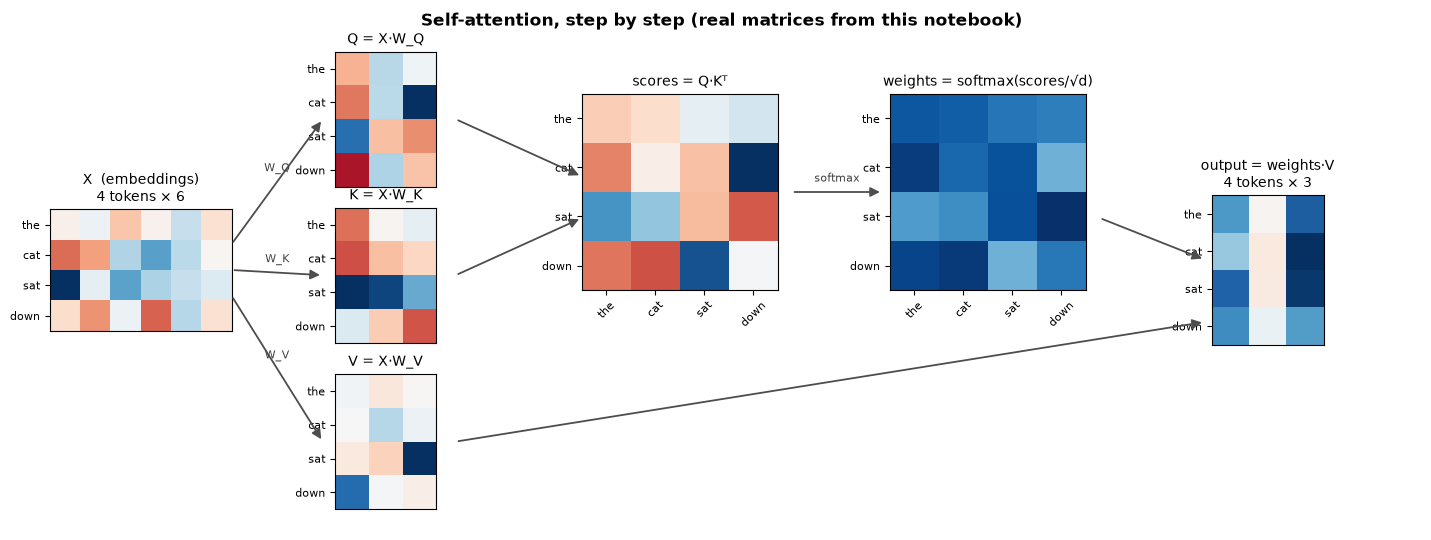

In [6]:
from matplotlib.patches import FancyArrowPatch

fig = plt.figure(figsize=(14, 5.2))
def panel(rect, M, title, rows, cols=None, cmap="RdBu_r"):
    ax = fig.add_axes(rect)
    lim = np.abs(M).max()
    ax.imshow(M, cmap=cmap, vmin=-lim if cmap == "RdBu_r" else 0, vmax=lim)
    ax.set_title(title, fontsize=10)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=8)
    if cols is None:
        ax.set_xticks([])
    else:
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, fontsize=8, rotation=45)
    for s in ax.spines.values(): s.set_visible(True)
    return ax

panel([0.02, 0.30, 0.13, 0.40], X, "X  (embeddings)\n4 tokens × 6", tokens)
panel([0.22, 0.66, 0.08, 0.26], Q,  "Q = X·W_Q", tokens)
panel([0.22, 0.36, 0.08, 0.26], K_, "K = X·W_K", tokens)
panel([0.22, 0.04, 0.08, 0.26], V_, "V = X·W_V", tokens)
panel([0.40, 0.45, 0.14, 0.40], S, "scores = Q·Kᵀ", tokens, tokens)
panel([0.62, 0.45, 0.14, 0.40], A, "weights = softmax(scores/√d)", tokens, tokens, cmap="Blues")
panel([0.85, 0.30, 0.08, 0.40], Z, "output = weights·V\n4 tokens × 3", tokens)

overlay = fig.add_axes([0, 0, 1, 1]); overlay.axis("off"); overlay.set_xlim(0, 1); overlay.set_ylim(0, 1)
def arrow(a, b, text=None):
    overlay.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=14, color="0.3", lw=1.3))
    if text:
        overlay.text((a[0] + b[0]) / 2, (a[1] + b[1]) / 2 + 0.02, text, ha="center", fontsize=8, color="0.25")
arrow((0.15, 0.55), (0.215, 0.79), "W_Q"); arrow((0.15, 0.50), (0.215, 0.49), "W_K"); arrow((0.15, 0.45), (0.215, 0.17), "W_V")
arrow((0.31, 0.79), (0.40, 0.68)); arrow((0.31, 0.49), (0.40, 0.60))
arrow((0.55, 0.65), (0.615, 0.65), "softmax")
arrow((0.77, 0.60), (0.845, 0.52)); arrow((0.31, 0.17), (0.845, 0.40))
overlay.text(0.5, 0.97, "Self-attention, step by step (real matrices from this notebook)", ha="center", fontsize=12, weight="bold")
au.save_fig(fig, "03_qkv_flow.png")
plt.show()

## Key takeaways

- Attention is a **soft dictionary lookup**: match a query against all keys, softmax the scores into weights, return the weighted average of the values.
- The **scale** of the scores controls how *hard* the lookup is.
- In practice each token creates its own **query, key and value** with three learned matrices $W_Q, W_K, W_V$.

### ✏️ Exercise 1

In the library example, change the query to `[1.0, 0.0, 0.0]` ("pure biology"). Which book gets the biggest weight, and what is the output?

<details>
<summary><b>Show solution</b></summary>

```python
q_bio = np.array([1.0, 0.0, 0.0])
w = au.softmax(K @ q_bio)
print(dict(zip(books, w.round(3))), w @ V)
```



</details>

### ✏️ Exercise 2

Write a function `soft_lookup(q, K, V, scale)` and show that with `scale=100` the output is (almost) exactly the value of the best-matching book.

<details>
<summary><b>Show solution</b></summary>

```python
def soft_lookup(q, K, V, scale=1.0):
    w = au.softmax(scale * (K @ q))
    return w @ V
print(soft_lookup(q, K, V, 100), "vs", V[np.argmax(K @ q)])
```



</details>

### ✏️ Exercise 3

Check that self-attention output for one token is a convex combination of the value rows: verify `Z[1] == A[1] @ V_` and that all `A[1]` entries are between 0 and 1.

<details>
<summary><b>Show solution</b></summary>

```python
print(np.allclose(Z[1], A[1] @ V_), A[1].min() >= 0, A[1].max() <= 1)
```



</details>